In [1]:
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from gwlens.tools import halo
import astropy.units as u

plotting.apply_figure_style()


### Halo

100000.0
NFW Halo Summary:
  M_200       = 1.00e+05 solMass 
  c           = 82.62966323168075
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.95746 kpc
  r_s         = 0.01159 kpc 
  rho_s       = 1.49e+09 solMass / kpc3 

104761.57527896641
NFW Halo Summary:
  M_200       = 1.05e+05 solMass 
  c           = 82.13149347873156
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.97242 kpc
  r_s         = 0.01184 kpc 
  rho_s       = 1.46e+09 solMass / kpc3 

109749.87654930567
NFW Halo Summary:
  M_200       = 1.10e+05 solMass 
  c           = 81.63632716417294
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.98762 kpc
  r_s         = 0.01210 kpc 
  rho_s       = 1.44e+09 solMass / kpc3 

114975.69953977356
NFW Halo Summary:
  M_200       = 1.15e+05 solMass 
  c           = 81.144146180438
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 sol

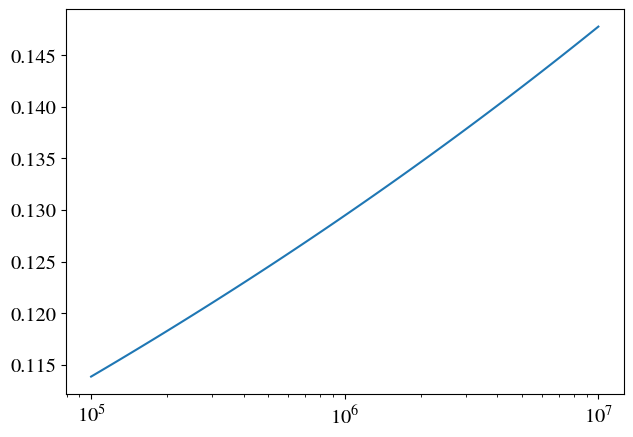

In [2]:
mass =  np.logspace(5,7,100)
k_value = []
for m in mass:
    print(m)
    Halo = halo.NFW(M200 = m, zl = 0.5)
    Halo.summary()

    k_val = Halo.scaling_ratio(zs = 1.0)
    k_value.append(k_val)
    #k_val =  Halo.scaling_ratio(Dl = 10*u.kpc, Ds= 20 *u.kpc, Dls = 10* u.kpc)
    w = Halo.Dimensionless_Frequency(f= 200)
print("w:",w)    
print("Normalization for GWLENS",k_val)
print("Normalization for GLoW:",1/k_val)
plt.semilogx(mass,k_value)


In [ ]:
from scipy.special import jv
def potential(k, x):
    u = k * x
    return np.where(
        u <= 1,
        0.5 * (np.log(np.maximum(u, 1e-300) / 2)**2
            - np.arctanh(np.sqrt(np.maximum(1 - u**2, 0)))**2),
        0.5 * (np.log(u / 2)**2
            + np.arctan(np.sqrt(np.maximum(u**2 - 1, 0)))**2)
    )   

def F_eps_NFW(w, y1,k,y2=0, N=5000, eps=0.002):

        """
        Docstring for F_eps_NFW
        
        :param w: Dimensionless frequency
        :param y1: Impact parameter 
        :param y2: Impact parameter (set to 0 )
        :param k: Normalization constant , consistent with GLoW NFW normalization
        :param N: Grid resolution
        :param eps: regulaization
        """ 
        y   = np.sqrt(y1**2 + y2**2)
        w_c = w * (1.0 + 1j * eps)
        L   = max(y, 0.0) + max(3.5, 4.0 / np.sqrt(w * eps), 2.5 * k)
        
        r   = np.linspace(0, L, N + 1)[1:]
        dr  = r[1] - r[0]

        psi       = potential(k, r)
        phi_r     = 0.5 * (r**2 + y**2) - psi
        J0        = jv(0, w_c * y * r)
        integrand = np.exp(1j * w_c * phi_r) * J0 * r
        return (w / 1j) * np.sum(integrand) * dr

### comparing the Fourier Integral and $\epsilon$- Regularization technique in GWLENS 

k=4.0, y=0.6 | ε-reg: 2.4s  GLoW: 0.0s


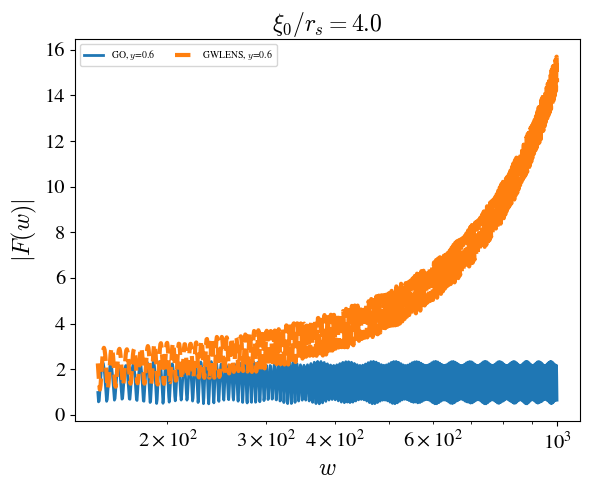

Epsilon_finished in: 2.38230299949646
Glow_finished in: 0.003555774688720703


In [4]:
from mpmath import mp
import time
from glow import time_domain_c, freq_domain_c, lenses
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
import gc

plotting.apply_figure_style()
mp.dps = 50  # reduce from 400 unless you specifically need that precision

# --- Parameters ---
k_values = [4.0]          # ← add/remove k values here
y_fixed  = [0.6]
w_val    = np.linspace(150,1000, 2000)
nfw_lens = nfw.NFW1()

# --- Subplots: one panel per k_fixed ---
fig, axes = plt.subplots(1, len(k_values), figsize=(6 * len(k_values), 5), sharey=True)

if len(k_values) == 1:          # ensure axes is always iterable
    axes = [axes]

for ax, k_fixed in zip(axes, k_values):
    for yi in y_fixed:

        # --- GWLENS epsilon regularisation ---
        start_eps = time.time()
        F_eps = np.array([
            nfw_lens.F_eps_NFW(w=wi, y1=yi, k=k_fixed, N=8000, eps=0.002)
            for wi in w_val
        ])
        end_eps = time.time()
        F_go = np.array([nfw_lens.Amplification(w = wi,y = yi,rs=k_fixed) for wi in w_val])

        # --- GLoW ---
        start_glow = time.time()
        Psi_cls = lenses.Psi_NFW
        Psi_tmp = Psi_cls()
        p_phys_default, p_prec_default = Psi_tmp.default_params()

        p_phys = dict(p_phys_default)
        p_phys['name'] = 'NFW'
        p_phys['psi0'] = 1.0
        p_phys['xs']   = 1 / k_fixed

        p_prec = dict(p_prec_default)
        p_prec['eps_soft'] = 1e-15
        p_prec['eps_NFW']  = 0.001

        Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)
        It_nfw  = time_domain_c.It_SingleIntegral_C(Psi_nfw, yi)
        Fw_nfw  = freq_domain_c.Fw_FFT_C(It_nfw)
        w_glow  = Fw_nfw.w_grid
        
        #ax.semilogx(w_glow, np.abs(Fw_nfw.eval_Fw(w_glow)),lw=2, label=f"GLoW, $y$={yi}")
        ax.semilogx(w_val, np.abs(F_go),lw=2, label=f"GO, $y$={yi}")
        
        ax.semilogx(w_val, np.abs(F_eps),ls="--",lw=3, label=f"GWLENS, $y$={yi}")

        end_glow = time.time()
        print(f"k={k_fixed}, y={yi} | ε-reg: {end_eps-start_eps:.1f}s  GLoW: {end_glow-start_glow:.1f}s")

        del It_nfw, Fw_nfw, Psi_nfw   # free C objects each iteration
        gc.collect()

    ax.set_xlabel("$w$")
    ax.set_title(f"$\\xi_0/r_s = {k_fixed}$")
    ax.legend(fontsize=7, ncol=2)

axes[0].set_ylabel("$|F(w)|$")
fig.tight_layout()
#plt.savefig("NFW_comparison_lowk.png", bbox_inches="tight")
plt.show()

print("Epsilon_finished in:",end_eps-start_eps)
print("Glow_finished in:",end_glow-start_glow)

(1.00683713051466625438606100342744353318162009960116280541079395145477118582147610597314617220644624444743999753602115440855057140932826856827836716848934199759190364214541582486263724452473709176136385816219977683495282996030474546906606973144002062625011146187100699059834789010570658653819650325559818748135547754305579291394675852817860476580090560336354356933826284011572090189441744025574821501 - 0.003279946129030820352986094201761803879305786965669548209775079307395631344991218319066564811247141415485278337588415616922524486195710708804390752265808972462628932220877156577710402857570530433363822825123837390653612926481077382909904662826747703694516428643805864275787617802240102286689714158161634966151153648896812270856749458626447655918881850374142679684552166749638860524540172886736366119278j)


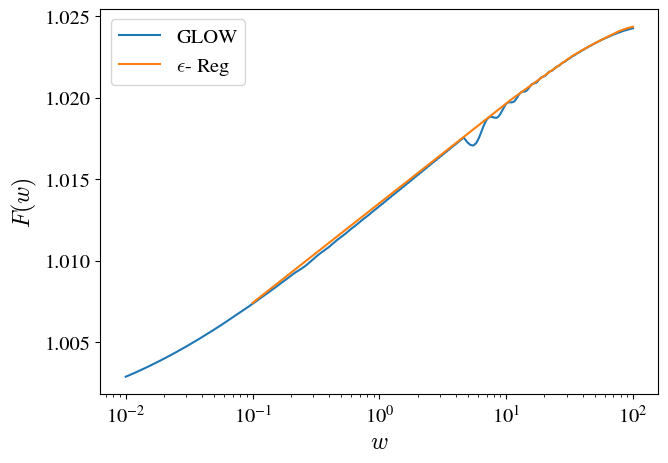

In [ ]:
It_nfw = time_domain_c.It_SingleIntegral_C(Psi_nfw, 0.1)
Fw_nfw = freq_domain_c.Fw_FFT_C(It_nfw)
w_glow = Fw_nfw.w_grid
plt.semilogx(w_glow,np.abs(Fw_nfw.eval_Fw(w_glow)),label="GLOW")
#plt.semilogx(w_val,np.abs(F_fi), label="Fourier-Integral")
plt.semilogx(w_val, np.abs(F_eps), label="$\epsilon$- Reg")
plt.legend()
plt.xlabel("$w$")
plt.ylabel("$F(w)$")


### Meshgrid plot


In [ ]:
w_val = np.logspace(-1,2,100)
y_val = np.linspace(0,5,100)

W,Y = np.meshgrid(w_val,y_val)
Z = np.zeros_like(W)


In [21]:
nfw_lens.solve_images(y1 = 0.05,y2= 0, rs = 0.12)

[{'position': (np.float64(0.051972262710834334), np.float64(0.0)),
  'magnification': np.float64(1.0724226153518828),
  'type': 'minimum',
  'Morse': 0,
  'method': 'numeric',
  'fermat_potential': np.float64(-5.41678836854271e-05),
  'dimensionless_time_delay': np.float64(0.0)}]

/tmp/ipykernel_3677287/1303198735.py:7: RuntimeWarning: divide by zero encountered in arctanh
  - np.arctanh(np.sqrt(np.maximum(1 - u**2, 0)))**2),
/tmp/ipykernel_3677287/4047452345.py:58: RuntimeWarning: divide by zero encountered in arctanh
  np.where(s > 0.0, np.arctanh(s) / s, 1.0),
/tmp/ipykernel_3677287/4047452345.py:58: RuntimeWarning: invalid value encountered in divide
  np.where(s > 0.0, np.arctanh(s) / s, 1.0),
/tmp/ipykernel_3677287/4047452345.py:60: RuntimeWarning: invalid value encountered in divide
  np.where(t > 0.0, np.arctan(t) / t, 1.0),


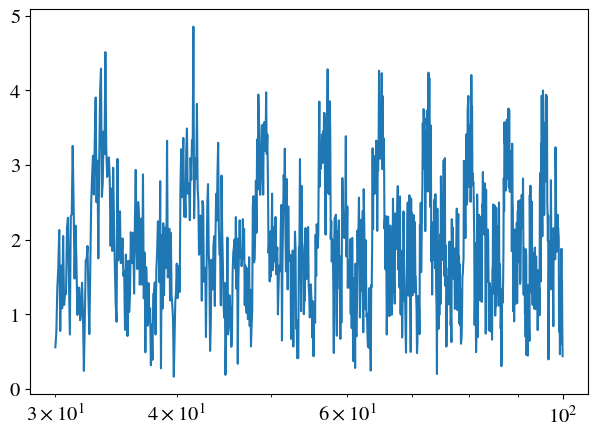

In [ ]:
from scipy.special import jv
from scipy.special import factorial as sp_fac


def potential(k, x):
    u  = np.maximum(k * x, 1e-300)

    a  = np.log(u / 2.0)                                     # ln(u/2), always negative for u<2
    
    # u <= 1 : factor  a² − b² = (a−b)(a+b)  to avoid catastrophic cancellation
    s     = np.sqrt(np.maximum(1.0 - u**2, 0.0))
    b     = np.arctanh(s)                                    # arctanh(√(1−u²))
    leq1  = 0.5 * (a - b) * (a + b)                         # stable for all u ≤ 1

    # u > 1 : no cancellation issue (both terms are positive and additive)
    t     = np.sqrt(np.maximum(u**2 - 1.0, 0.0))
    gt1   = 0.5 * (a**2 + np.arctan(t)**2)


def filon_weights_vec(theta, K=16):
    """
    Vectorized Filon–Lagrange weights for an array of theta values.
    Stable Taylor series for |theta| < 0.5, direct recurrence otherwise.
    """
    theta = np.asarray(theta, dtype=float)
    A0 = np.empty_like(theta, dtype=complex)
    A1 = np.empty_like(theta, dtype=complex)
    A2 = np.empty_like(theta, dtype=complex)

    small =  np.abs(theta) < 0.5
    large = ~small

    # ── Taylor branch ─────────────────────────────────────────────────
    if small.any():
        th = theta[small]
        k  = np.arange(K, dtype=float)
        # (iθ)^k / k!  for every panel (panels × K matrix)
        qk = (1j * th[:, None])**k / sp_fac(k, exact=False)
        p2 = 2.0**k
        I0 = (qk * (2.0 * p2 / (k + 1.0))).sum(axis=1)
        I1 = (qk * (4.0 * p2 / (k + 2.0))).sum(axis=1)
        I2 = (qk * (8.0 * p2 / (k + 3.0))).sum(axis=1)
        A0[small] = 0.5*(I2 - 3.0*I1 + 2.0*I0)
        A1[small] = -(I2 - 2.0*I1)
        A2[small] = 0.5*(I2 - I1)

    # ── Direct branch ─────────────────────────────────────────────────
    if large.any():
        th  = theta[large]
        P   = np.exp(2j * th)
        q   = 1j * th
        I0  = (P - 1.0) / q
        I1  = 2.0*P/q - I0/q
        I2  = 4.0*P/q - 2.0*I1/q
        A0[large] = 0.5*(I2 - 3.0*I1 + 2.0*I0)
        A1[large] = -(I2 - 2.0*I1)
        A2[large] = 0.5*(I2 - I1)

    return A0, A1, A2


def alpha_vec(r, rs):
    """
    Vectorized deflection angle α(r) = [ln(rs·r/2) + h(u)] / r, u = rs·r.
    Returns 0 at r = 0.
    """
    r   = np.asarray(r, dtype=float)
    u   = rs * np.maximum(r, 1e-300)
    lnu = np.log(u / 2.0)

    s   = np.sqrt(np.maximum(1.0 - u**2, 0.0))
    t   = np.sqrt(np.maximum(u**2 - 1.0, 0.0))

    h_u = np.where(u < 1.0 - 1e-7,
                   np.where(s > 0.0, np.arctanh(s) / s, 1.0),
                   np.where(u > 1.0 + 1e-7,
                            np.where(t > 0.0, np.arctan(t) / t, 1.0),
                            1.0))

    alpha = np.where(r > 1e-12, (lnu + h_u) / r, 0.0)
    return alpha


def F_filon_NFW( w, y, rs, N=None, r_max=None, tail_order=1):
    """
    NFW amplification factor via generalized Filon in r-space.

    The integral is split as:
        F = (w/i) ∫₀^{r_max} g(r) · e^{iw·φ(r)} dr

    where
        g(r)   = r · J₀(wyr)          ← slowly varying (freq ~wy per unit r)
        φ(r)   = r²/2 + y²/2 − ψ(r)  ← full Fermat potential (NOT split)

    Per panel [r_{2k}, r_{2k+2}], linearize φ around the left node:
        φ(r) ≈ φ(r_{2k}) + φ'(r_{2k})·(r − r_{2k}),  φ'(r) = r − α(r)
        θ_k  = w · φ'(r_{2k}) · h     ← local Filon parameter

    The per-panel θ_k varies continuously: near images φ'≈ ±y → θ small
    → Simpson; in the oscillatory wings θ large → Filon handles exactly.

    Parameters
    ----------
    w          : float  – dimensionless frequency
    y          : float  – impact parameter
    rs         : float  – NFW scale parameter
    N          : int    – number of panels (even; default adaptive)
    r_max      : float  – integration cutoff (default adaptive)
    tail_order : int    – asymptotic tail correction order (0, 1, or 2)

    Returns
    -------
    F : complex
    """
    # ── Limits ───────────────────────────────────────────────────────
    if r_max is None:
        r_max = max(y, 0.0) + max(5.0 / rs, 5.0)

    # ── Grid: only needs to resolve g(r) = r·J₀(wyr), freq ~wy ──────
    if N is None:
        N = max(256, int(10 * w * y * r_max / np.pi) + 1)
        if N % 2: N += 1
    elif N % 2:
        N += 1

    h = r_max / N
    r = np.linspace(0.0, r_max, N + 1)

    # ── NFW quantities at all nodes ───────────────────────────────────
    psi       = potential(rs, np.maximum(r, 1e-300))
    psi[0]    = 0.0
    alpha     = alpha_vec(r, rs)       # vectorized; returns 0 at r=0

    phi       = 0.5*r**2 + 0.5*y**2 - psi   # Fermat potential φ(r)
    dphi      = r - alpha                    # φ'(r) = r − α(r)

    # ── Slowly-varying amplitude g(r) = r · J₀(wyr) ──────────────────
    J0        = jv(0, w * y * r)             # real w
    g         = r * J0
    g[0]      = 0.0                          # r·J₀(0) = 0

    # ── Per-panel local Filon parameter θ_k = w·φ'(r_{2k})·h ─────────
    k_idx     = np.arange(N // 2)           # 0 … N/2−1
    lft       = 2 * k_idx                   # left node index 2k
    theta_k   = w * dphi[lft] * h           # shape (N/2,)

    A0k, A1k, A2k = filon_weights_vec(theta_k)

    # ── Exact phase at every node ─────────────────────────────────────
    eiphi  = np.exp(1j * w * phi)           # e^{iw·φ(r_j)}, shape (N+1,)

    # ── Composite sum ─────────────────────────────────────────────────
    # Each panel k contributes to nodes 2k, 2k+1, 2k+2 independently
    # (variable θ means panels cannot be merged into the simple
    # even/odd split of the uniform-θ case)
    S = (  A0k * g[lft]   * eiphi[lft]
         + A1k * g[lft+1] * eiphi[lft+1]
         + A2k * g[lft+2] * eiphi[lft+2] )

    integral = h * S.sum()

    # ── Asymptotic tail ∫_{r_max}^∞ g(r) e^{iw·φ(r)} dr ─────────────
    # IBP: ≈ g(r_max)/(iw·φ'(r_max)) · e^{iw·φ(r_max)} + …
    # Note: φ' = r−α → r for large r, so tail ~ g(r_max)/(iw·r_max)
    if tail_order >= 1 and abs(dphi[-1]) > 1e-10:
        fT        = g[-1] * np.exp(1j * w * phi[-1])
        integral += fT / (1j * w * dphi[-1])

    return (w / 1j) * integral










w = np.linspace(30,100,1000)
F_filon = np.array([F_filon_NFW(w=wi,y= 0.2,rs= 0.1) for wi in w])
plt.semilogx(w,np.abs(F_filon))

(2000, 1, 1, 2)
[0.1] [3.]


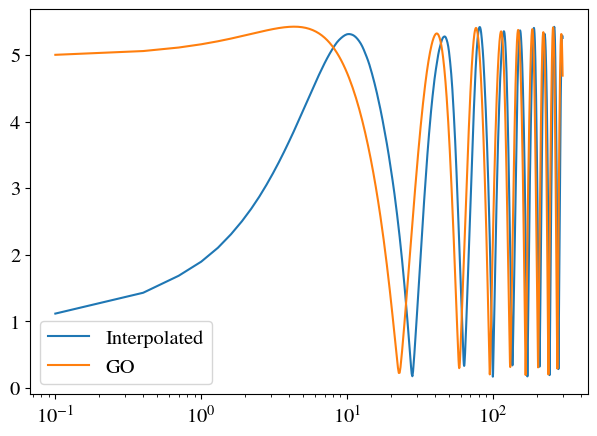

In [17]:
import numpy as np
import h5py
from scipy.interpolate import UnivariateSpline
from astropy import units as u
from astropy.constants import G,c
import matplotlib.pyplot as plt

nfw_lens = nfw.NFW1()


file = "/work/sreekanth/codes/GWLENS/tests/nfw/outdir/interpolation/result_w2000.hdf5"
with h5py.File(file, 'r') as file:
    w_values = file['w_values'][:]
    y_values = file['y_values'][:]
    rs_values = file['rs_values'][:]
    data = file['results'][:]  # (len(w), len(y), 2)
print(data.shape)
real_data = data[:, :, 0, 0]
imag_data = data[:, :, 0, 1]

real_spline = UnivariateSpline(w_values, real_data, k=3,s=0)
imag_spline = UnivariateSpline(w_values, imag_data, k=3,s=0)

w_test = np.linspace(0.1,300,1000)
real_interp = real_spline(w_test)
imag_interp = imag_spline(w_test)
F_interp = real_interp + 1j * imag_interp
print(y_values,rs_values)
#GO
#F_go = np.array(nfw_lens.Amplification(w = w_test,y = y_values,rs=rs_values))
F_go = np.array([nfw_lens.Amplification(w = wi,y = 0.1,rs=rs_values[0]) for wi in w_test])
#print(nfw_lens.Amplification(w = 10,y = 0.1,rs=3.0))

plt.semilogx(w_test, np.abs(F_interp), label="Interpolated")
plt.semilogx(w_test, np.abs(F_go), label="GO")
plt.legend()